<a href="https://colab.research.google.com/github/fahad11-mikey/MLA-0204/blob/main/Experiment-20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Sales Prediction MAE: 758.5647921037632
R2 Score: 0.9663787114846887
Predicted sales for next 6 months:
Month 49: 31635.75
Month 50: 32074.73
Month 51: 32513.71
Month 52: 32952.70
Month 53: 33391.68
Month 54: 33830.66


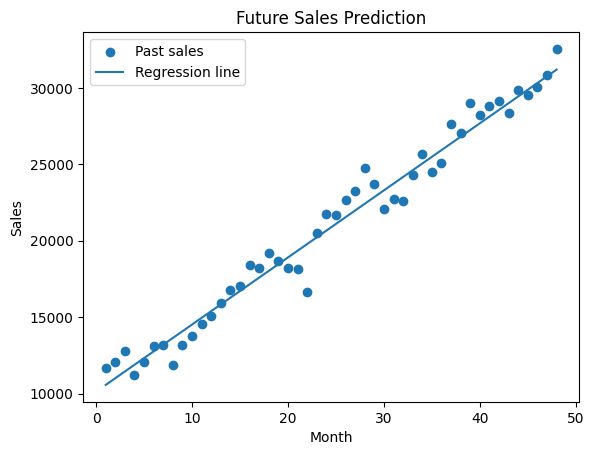

In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

np.random.seed(20)
months = np.arange(1, 49).reshape(-1, 1)
sales = 10000 + months.ravel() * 450 + 1200 * np.sin(months.ravel() * 2 * np.pi / 12) + np.random.normal(0, 700, 48)

X_train, X_test, y_train, y_test = train_test_split(
    months, sales, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Sales Prediction MAE:", mean_absolute_error(y_test, pred))
print("R2 Score:", r2_score(y_test, pred))

future_months = np.arange(49, 55).reshape(-1, 1)
future_sales = model.predict(future_months)
print("Predicted sales for next 6 months:")
for month, amount in zip(range(49, 55), future_sales):
    print(f"Month {month}: {amount:.2f}")

plt.scatter(months, sales, label="Past sales")
plt.plot(months, model.predict(months), label="Regression line")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.title("Future Sales Prediction")
plt.legend()
plt.show()